In [23]:
!pip install seaborn lightgbm pandas numpy scipy statsmodels prophet tensorflow scikit-learn --q
print("Done")

Done


  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-health-checking 1.74.0 requires protobuf<7.0.0,>=6.31.1, but you have protobuf 4.25.9 which is incompatible.
livekit 1.1.8 requires numpy>=1.26, but you have numpy 1.23.5 which is incompatible.
livekit-agents 1.5.13 requires numpy>=1.26.0, but you have numpy 1.23.5 which is incompatible.
livekit-plugins-silero 1.5.13 requires numpy>=1.26, but you have numpy 1.23.5 which is incompatible.
livekit-plugins-turn-detector 1.5.13 requires numpy>=1.26, but you have numpy 1.23.5 which is incompatible.
local-livekit-plugins 0.1.0 requires numpy>=1.24.0, but you have numpy 1.23.5 which is incompatible.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.23.5 which is incompatible.
opencv-python-headles

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("data.csv") 
print("Done")

Done


In [3]:
df.head()

,Unnamed: 0,date,open,high,low,close,volume,stock_name
0,0,2016-05-31,NaN,NaN,NaN,1.25,NaN,abbeybds
1,1,2016-06-06,NaN,NaN,NaN,1.25,NaN,abbeybds
2,2,2016-06-20,NaN,NaN,NaN,1.25,NaN,abbeybds
3,3,2016-06-21,NaN,NaN,NaN,1.25,NaN,abbeybds
4,4,2016-06-23,NaN,NaN,NaN,1.25,NaN,abbeybds


In [5]:
df = df[["date", "close", "stock_name"]]
df.head()

,date,close,stock_name
0,2016-05-31,1.25,abbeybds
1,2016-06-06,1.25,abbeybds
2,2016-06-20,1.25,abbeybds
3,2016-06-21,1.25,abbeybds
4,2016-06-23,1.25,abbeybds


In [7]:
df.shape

(306872, 3)

In [8]:
df.drop_duplicates(inplace=True)
df.shape

C:\Users\Tunji.obidokun\AppData\Local\Temp\ipykernel_9872\3054484884.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop_duplicates(inplace=True)


(306872, 3)

In [14]:
df

,date,close,stock_name
0,2016-05-31,1.25,abbeybds
1,2016-06-06,1.25,abbeybds
2,2016-06-20,1.25,abbeybds
3,2016-06-21,1.25,abbeybds
4,2016-06-23,1.25,abbeybds
...,...,...,...
306867,2026-06-22,23.40,zichis
306868,2026-06-23,24.67,zichis
306869,2026-06-24,24.90,zichis
306870,2026-06-25,24.90,zichis


In [15]:
df.isnull().sum()

date          0
close         0
stock_name    0
dtype: int64

In [12]:
df.describe(include="all")

,date,close,stock_name
count,306872,306872.000000,306872
unique,2492,NaN,146
top,2026-05-11,NaN,afriprud
freq,137,NaN,2492
mean,NaN,1778.159488,NaN
std,NaN,41364.664135,NaN
min,NaN,0.200000,NaN
25%,NaN,0.900000,NaN
50%,NaN,3.650000,NaN
75%,NaN,17.750000,NaN


In [13]:
df_pivot = df.pivot(
    index="stock_name",
    columns="date",
    values="close"
)

df_pivot

date,2016-05-25,2016-05-26,2016-05-27,2016-05-31,2016-06-01,2016-06-02,2016-06-03,2016-06-06,2016-06-07,2016-06-08,...,2026-06-15,2026-06-16,2026-06-17,2026-06-18,2026-06-19,2026-06-22,2026-06-23,2026-06-24,2026-06-25,2026-06-26
stock_name,,,,,,,,,,,,,,,,,,,,,
abbeybds,NaN,NaN,NaN,1.25,NaN,NaN,NaN,1.25,NaN,NaN,...,10.30,10.30,10.10,10.10,10.1,9.15,8.30,8.25,8.70,8.05
abctrans,NaN,NaN,NaN,0.50,0.50,NaN,NaN,NaN,0.50,NaN,...,7.80,7.80,7.80,7.80,7.8,7.80,7.80,7.80,7.80,7.80
academy,0.63,NaN,0.66,0.66,0.66,0.66,0.69,0.69,NaN,NaN,...,8.10,8.10,8.10,8.10,8.1,8.10,8.10,7.30,6.70,6.70
accesscorp,5.61,5.98,5.96,5.67,5.28,5.29,5.56,5.56,5.30,5.35,...,24.35,23.95,23.50,23.00,22.8,22.65,23.00,23.00,23.00,22.95
afrinsure,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.50,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
wapco,80.85,83.01,83.01,76.57,73.40,77.07,80.01,80.01,80.01,80.01,...,330.00,330.00,330.00,330.00,315.1,316.00,317.40,317.40,317.40,317.40
wapic,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,...,2.55,2.55,2.55,2.50,2.5,2.56,2.54,2.55,2.38,2.38
wemabank,0.78,0.78,0.80,0.78,0.76,0.77,0.76,0.76,0.76,0.76,...,30.90,30.90,30.00,29.25,30.0,30.00,29.00,28.20,27.00,27.00


In [6]:
# ============================================================
# CELL 1: IMPORTS & CONFIGURATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import joblib
import warnings
import os
from datetime import datetime, timedelta
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("viridis")
%matplotlib inline

# Configuration
DATA_PATH = "data.csv"  # <--- CHANGE THIS TO YOUR FILE PATH
MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

# LightGBM Hyperparameters (Optimized for financial time-series)
LGBM_PARAMS = {
    'n_estimators': 800,
    'learning_rate': 0.03,
    'num_leaves': 45,
    'max_depth': 8,
    'min_child_samples': 20,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.5,
    'reg_lambda': 0.8,
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}

print("✅ Setup complete!")

✅ Setup complete!


In [7]:
# ============================================================
# CELL 2: LOAD AND EXPLORE RAW DATA
# ============================================================
df_raw = pd.read_csv(DATA_PATH, parse_dates=['date'])

print(f"📊 Raw Dataset Shape: {df_raw.shape}")
print(f"📅 Date Range: {df_raw['date'].min()} to {df_raw['date'].max()}")
print(f"🏢 Unique Stocks: {df_raw['stock_name'].nunique()}")
print("\n🔍 First 5 Rows:")
df_raw.head()

📊 Raw Dataset Shape: (306872, 8)
📅 Date Range: 2016-05-25 00:00:00 to 2026-06-26 00:00:00
🏢 Unique Stocks: 146

🔍 First 5 Rows:


,Unnamed: 0,date,open,high,low,close,volume,stock_name
0,0,2016-05-31,NaN,NaN,NaN,1.25,NaN,abbeybds
1,1,2016-06-06,NaN,NaN,NaN,1.25,NaN,abbeybds
2,2,2016-06-20,NaN,NaN,NaN,1.25,NaN,abbeybds
3,3,2016-06-21,NaN,NaN,NaN,1.25,NaN,abbeybds
4,4,2016-06-23,NaN,NaN,NaN,1.25,NaN,abbeybds


In [8]:
# Check for missing values per column
print("\n🧹 Missing Values Per Column:")
print(df_raw.isnull().sum())

# Check how many stocks have sufficient data (> 30 days)
stock_counts = df_raw.groupby('stock_name').size()
valid_stocks = stock_counts[stock_counts >= 30].index
print(f"\n✅ Stocks with >= 30 trading days: {len(valid_stocks)} out of {df_raw['stock_name'].nunique()}")


🧹 Missing Values Per Column:
Unnamed: 0         0
date               0
open          306872
high          306872
low           306872
close              0
volume        306872
stock_name         0
dtype: int64

✅ Stocks with >= 30 trading days: 146 out of 146


In [9]:
# ============================================================
# CELL 3: FEATURE ENGINEERING FUNCTIONS (PURELY FROM CLOSE)
# ============================================================

def calculate_rsi(series, period=14):
    """Relative Strength Index (RSI)"""
    delta = series.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

def calculate_macd(series, fast=12, slow=26, signal=9):
    """MACD, Signal Line, and Histogram"""
    ema_fast = series.ewm(span=fast, adjust=False).mean()
    ema_slow = series.ewm(span=slow, adjust=False).mean()
    macd_line = ema_fast - ema_slow
    macd_signal = macd_line.ewm(span=signal, adjust=False).mean()
    macd_hist = macd_line - macd_signal
    return macd_line, macd_signal, macd_hist

def engineer_features(df_stock):
    """
    Takes a single stock's DataFrame (sorted by date).
    Engineers features using ONLY the 'close' column.
    Returns DataFrame with features + target (5-day forward return).
    """
    df = df_stock.copy()
    df = df.sort_values('date').reset_index(drop=True)
    
    # --- 1. Lagged Returns (Past performance) ---
    for lag in [1, 2, 3, 4, 5]:
        df[f'return_lag_{lag}'] = df['close'].pct_change(periods=lag)
        df[f'close_lag_{lag}'] = df['close'].shift(lag)
    
    # --- 2. Rolling Statistics (Trend & Volatility) ---
    for window in [5, 10, 20]:
        df[f'ma_{window}'] = df['close'].rolling(window).mean()
        df[f'std_{window}'] = df['close'].rolling(window).std()
        # Price position relative to MA (how far above/below)
        df[f'dist_ma_{window}'] = (df['close'] - df[f'ma_{window}']) / df[f'ma_{window}']
    
    # --- 3. Momentum Indicators ---
    df['rsi_14'] = calculate_rsi(df['close'], period=14)
    macd, macd_signal, macd_hist = calculate_macd(df['close'])
    df['macd_line'] = macd
    df['macd_signal'] = macd_signal
    df['macd_histogram'] = macd_hist
    
    # --- 4. Volatility Ratio (Current vs Historical) ---
    df['vol_ratio_5_20'] = df['std_5'] / df['std_20']
    
    # --- 5. Date Features (Market Seasonality) ---
    df['day_of_week'] = df['date'].dt.dayofweek
    df['month'] = df['date'].dt.month
    df['quarter'] = df['date'].dt.quarter
    df['day_of_year'] = df['date'].dt.dayofyear
    
    # --- 6. TARGET: 5-day forward percentage return ---
    df['target_5d_return'] = df['close'].shift(-5) / df['close'] - 1
    
    # Drop rows where target is NaN (last 5 days of each stock)
    df = df.dropna(subset=['target_5d_return'])
    
    # Drop rows where any feature is NaN (due to rolling windows)
    df = df.dropna()
    
    return df

print("✅ Feature engineering functions defined!")

✅ Feature engineering functions defined!


In [10]:
# ============================================================
# CELL 4: APPLY FEATURE ENGINEERING TO ALL STOCKS
# ============================================================
# Filter to only valid stocks first
df_raw_filtered = df_raw[df_raw['stock_name'].isin(valid_stocks)]

all_features = []
for stock in valid_stocks:
    df_stock = df_raw_filtered[df_raw_filtered['stock_name'] == stock].copy()
    df_eng = engineer_features(df_stock)
    df_eng['stock_name'] = stock
    all_features.append(df_eng)

df_full = pd.concat(all_features, ignore_index=True)

print(f"📊 Engineered Dataset Shape: {df_full.shape}")
print(f"📅 Date Range in Engineered Set: {df_full['date'].min()} to {df_full['date'].max()}")
print(f"🏢 Unique Stocks in Engineered Set: {df_full['stock_name'].nunique()}")
df_full.head()

📊 Engineered Dataset Shape: (0, 37)
📅 Date Range in Engineered Set: NaT to NaT
🏢 Unique Stocks in Engineered Set: 0


,Unnamed: 0,date,open,high,low,close,volume,stock_name,return_lag_1,close_lag_1,...,rsi_14,macd_line,macd_signal,macd_histogram,vol_ratio_5_20,day_of_week,month,quarter,day_of_year,target_5d_return


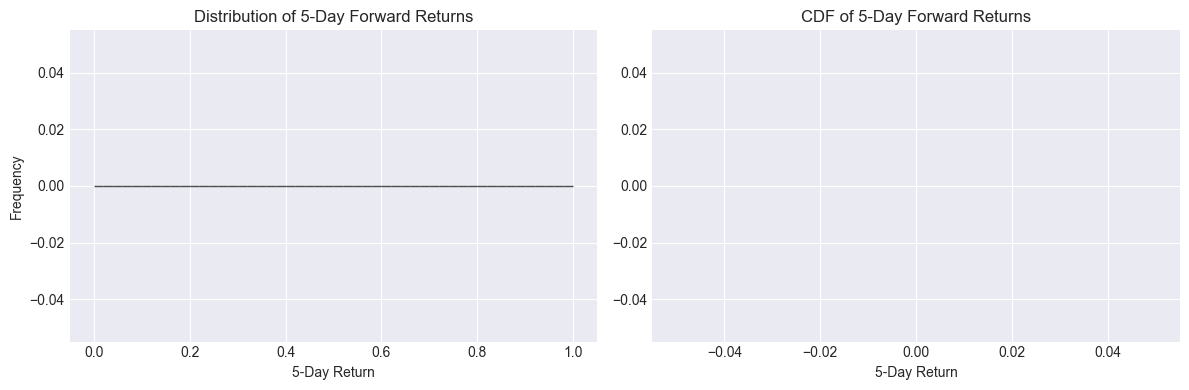

Mean Target: nan
Std Target: nan
Min: nan | Max: nan


In [13]:
# Check the distribution of the target variable
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
df_full['target_5d_return'].hist(bins=50, edgecolor='black', alpha=0.7)
plt.title('Distribution of 5-Day Forward Returns')
plt.xlabel('5-Day Return')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
df_full['target_5d_return'].hist(bins=50, cumulative=True, density=True, alpha=0.5)
plt.title('CDF of 5-Day Forward Returns')
plt.xlabel('5-Day Return')

plt.tight_layout()
plt.show()

print(f"Mean Target: {df_full['target_5d_return'].mean():.6f}")
print(f"Std Target: {df_full['target_5d_return'].std():.6f}")
print(f"Min: {df_full['target_5d_return'].min():.6f} | Max: {df_full['target_5d_return'].max():.6f}")

In [16]:
df.head()

,date,close,stock_name
0,2016-05-31,1.25,abbeybds
1,2016-06-06,1.25,abbeybds
2,2016-06-20,1.25,abbeybds
3,2016-06-21,1.25,abbeybds
4,2016-06-23,1.25,abbeybds


In [17]:
import pandas as pd
import numpy as np
from scipy import stats

def analyze_stock(data: pd.DataFrame, stock_name: str) -> dict:
    """
    Analyze a single stock from the historical data and return metrics and forecasts.

    Parameters
    ----------
    data : pd.DataFrame
        Must contain columns: 'date', 'close', 'stock_name'
    stock_name : str
        The name of the stock to analyze.

    Returns
    -------
    dict
        A dictionary with the required output fields.
    """
    # Filter and sort
    df = data[data['stock_name'] == stock_name].copy()
    if df.empty:
        raise ValueError(f"Stock '{stock_name}' not found in the dataset.")
    
    df = df.sort_values('date').reset_index(drop=True)
    prices = df['close'].values
    dates = df['date'].values
    
    # Ensure enough data
    if len(prices) < 30:
        raise ValueError(f"Not enough historical data for {stock_name} (need at least 30 points).")
    
    # Daily returns
    returns = np.diff(prices) / prices[:-1]
    
    # Last known price
    last_price = prices[-1]
    
    # 7-day and 30-day returns (actual past returns)
    # Use the last 7 and 30 trading days; if not enough, use as much as available.
    n7 = min(7, len(prices) - 1)
    n30 = min(30, len(prices) - 1)
    ret_7d = (prices[-1] - prices[-1 - n7]) / prices[-1 - n7] if n7 > 0 else 0.0
    ret_30d = (prices[-1] - prices[-1 - n30]) / prices[-1 - n30] if n30 > 0 else 0.0
    
    # Volatility (annualized) based on last 30 daily returns
    recent_returns = returns[-30:] if len(returns) >= 30 else returns
    daily_std = np.std(recent_returns, ddof=1) if len(recent_returns) > 1 else 0.0
    annualized_vol = daily_std * np.sqrt(252)  # assuming 252 trading days/year
    
    # Trend using linear regression on last 60 days (or all if less)
    n_trend = min(60, len(prices))
    x = np.arange(n_trend)
    y = prices[-n_trend:]
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    trend = "Bullish" if slope > 0 else "Bearish"
    
    # Forecast next day and next 5 days using the regression line
    # We extrapolate one step beyond the last data point
    next_idx = n_trend  # the index for the next day if we consider the x from 0..n_trend-1
    next_day_price = intercept + slope * next_idx
    # For next 5 days, continue
    next_5_days = [intercept + slope * (next_idx + i) for i in range(1, 6)]
    
    # If forecasted price is negative or unrealistic, fallback to simple drift
    if next_day_price <= 0:
        # fallback: use average daily return over last 30 days
        avg_ret = np.mean(recent_returns) if len(recent_returns) > 0 else 0.0
        next_day_price = last_price * (1 + avg_ret)
        next_5_days = [last_price * (1 + avg_ret) ** (i+1) for i in range(5)]
    
    # Recommendation based on trend
    recommendation = "Buy" if trend == "Bullish" else "Sell"
    
    # Format output
    output = {
        "stock": stock_name,
        "next_day_price": round(next_day_price, 2),
        "next_5_days": [round(p, 2) for p in next_5_days],
        "trend": trend,
        "7_day_return_percentage": round(ret_7d * 100, 2),   # as percentage
        "30_day_return_percentage": round(ret_30d * 100, 2), # as percentage
        "volatility": round(annualized_vol, 4),   # decimal (e.g., 0.14)
        "recommendation": recommendation
    }
    return output



In [19]:
# Example usage:
# Load your CSV data
df = pd.read_csv('data.csv', parse_dates=['date'])
result = analyze_stock(df, 'abbeybds')
print(result)

{'stock': 'abbeybds', 'next_day_price': np.float64(8.54), 'next_5_days': [np.float64(8.55), np.float64(8.57), np.float64(8.59), np.float64(8.61), np.float64(8.62)], 'trend': 'Bullish', '7_day_return': np.float64(-20.3), '30_day_return': np.float64(18.38), 'volatility': np.float64(1.1277), 'recommendation': 'Buy'}


In [20]:
df = pd.read_csv('data.csv', parse_dates=['date'])
result = analyze_stock(df, 'gtco')
print(result)

{'stock': 'gtco', 'next_day_price': np.float64(137.9), 'next_5_days': [np.float64(138.04), np.float64(138.17), np.float64(138.31), np.float64(138.44), np.float64(138.57)], 'trend': 'Bullish', '7_day_return': np.float64(-0.85), '30_day_return': np.float64(-15.83), 'volatility': np.float64(0.4954), 'recommendation': 'Buy'}


In [24]:
import pandas as pd
import numpy as np
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# --- For ARIMA ---
from statsmodels.tsa.arima.model import ARIMA

# --- For Prophet ---
from prophet import Prophet

# --- For LSTM ---
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping


# --------------------------
# Helper functions
# --------------------------

def compute_common_metrics(prices):
    """
    Compute 7-day return, 30-day return, and annualized volatility
    from a numpy array of prices (sorted chronologically).
    """
    if len(prices) < 30:
        raise ValueError("Need at least 30 data points for metrics.")

    returns = np.diff(prices) / prices[:-1]
    last = prices[-1]

    n7 = min(7, len(prices) - 1)
    n30 = min(30, len(prices) - 1)
    ret_7d = (last - prices[-1 - n7]) / prices[-1 - n7] if n7 > 0 else 0.0
    ret_30d = (last - prices[-1 - n30]) / prices[-1 - n30] if n30 > 0 else 0.0

    recent_returns = returns[-30:] if len(returns) >= 30 else returns
    daily_std = np.std(recent_returns, ddof=1) if len(recent_returns) > 1 else 0.0
    vol = daily_std * np.sqrt(252)

    return {
        '7_day_return': round(ret_7d * 100, 2),
        '30_day_return': round(ret_30d * 100, 2),
        'volatility': round(vol, 4)
    }


def get_trend_and_recommendation(forecast_prices):
    """
    Given a list of forecasted prices (at least 2), determine trend and recommendation.
    """
    x = np.arange(len(forecast_prices))
    slope, _, _, _, _ = stats.linregress(x, forecast_prices)
    trend = "Bullish" if slope > 0 else "Bearish"
    rec = "Buy" if trend == "Bullish" else "Sell"
    return trend, rec


# --------------------------
# Model training & prediction functions
# --------------------------

def simple_forecast(dates, prices):
    """
    Simple linear regression on the last 60 days (or all if less).
    Returns (next_day_price, next_5_days).
    """
    n = min(60, len(prices))
    x = np.arange(n)
    y = prices[-n:]
    slope, intercept, _, _, _ = stats.linregress(x, y)
    next_idx = n
    next_day = intercept + slope * next_idx
    next_5 = [intercept + slope * (next_idx + i) for i in range(1, 6)]

    # Fallback if forecast is non-positive
    if next_day <= 0:
        avg_ret = np.mean(np.diff(prices) / prices[:-1]) if len(prices) > 1 else 0.0
        next_day = prices[-1] * (1 + avg_ret)
        next_5 = [prices[-1] * (1 + avg_ret) ** (i+1) for i in range(5)]

    return next_day, next_5


def arima_forecast(dates, prices):
    """
    Fit an ARIMA(5,1,0) model on the full series and forecast 6 steps ahead.
    Returns (next_day_price, next_5_days).
    """
    # Use a simple ARIMA(5,1,0) – can be tuned per stock but we keep it fixed.
    model = ARIMA(prices, order=(5, 1, 0))
    model_fit = model.fit()
    forecast = model_fit.forecast(steps=6)  # returns array of 6 steps
    next_day = forecast[0]
    next_5 = forecast[1:].tolist()
    return next_day, next_5


def prophet_forecast(dates, prices):
    """
    Fit Prophet model on the data and predict next 6 days.
    Returns (next_day_price, next_5_days).
    """
    # Prepare DataFrame for Prophet
    df = pd.DataFrame({'ds': dates, 'y': prices})
    model = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False)
    model.fit(df)
    # Create future dataframe for next 6 trading days (we assume trading days are consecutive)
    # Prophet works with calendar days; we need to create a sequence of dates.
    # Since we have trading days only, we can simply increment the last date by 1 day
    # but that may include weekends. To be safe, we use the last date and add 1 day for each step.
    last_date = dates[-1]
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=6)
    future = pd.DataFrame({'ds': future_dates})
    forecast = model.predict(future)
    preds = forecast['yhat'].values
    next_day = preds[0]
    next_5 = preds[1:].tolist()
    return next_day, next_5


def lstm_forecast(dates, prices):
    """
    Train a simple LSTM model on the last 100 days (or all) to predict the next day.
    Then use recursive forecasting to get next 5 days.
    Returns (next_day_price, next_5_days).
    """
    # Use a sliding window of 10 days to predict the next day
    window_size = 10
    # Ensure we have enough data
    if len(prices) < window_size + 1:
        raise ValueError("Not enough data for LSTM (need at least 11 points).")

    # Scale data
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaled = scaler.fit_transform(prices.reshape(-1, 1)).flatten()

    # Create sequences
    X, y = [], []
    for i in range(window_size, len(scaled)):
        X.append(scaled[i-window_size:i])
        y.append(scaled[i])
    X = np.array(X).reshape(-1, window_size, 1)
    y = np.array(y)

    # Build LSTM model
    model = Sequential([
        LSTM(50, activation='relu', input_shape=(window_size, 1)),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    # Early stopping to avoid overfitting
    early_stop = EarlyStopping(monitor='loss', patience=5, restore_best_weights=True)
    model.fit(X, y, epochs=50, batch_size=16, verbose=0, callbacks=[early_stop])

    # Recursive forecasting
    last_sequence = scaled[-window_size:].reshape(1, window_size, 1)
    forecasts_scaled = []
    current_seq = last_sequence.copy()
    for _ in range(6):
        pred_scaled = model.predict(current_seq, verbose=0)[0, 0]
        forecasts_scaled.append(pred_scaled)
        # Update sequence: drop first element and append prediction
        current_seq = np.roll(current_seq, -1)
        current_seq[0, -1, 0] = pred_scaled

    # Inverse transform
    forecasts = scaler.inverse_transform(np.array(forecasts_scaled).reshape(-1, 1)).flatten()
    next_day = forecasts[0]
    next_5 = forecasts[1:].tolist()
    return next_day, next_5


# --------------------------
# Main analysis function
# --------------------------

def analyze_stock_with_models(data: pd.DataFrame, stock_name: str) -> list:
    """
    For a given stock, run all four models and return a list of results.
    """
    # Filter and sort
    df = data[data['stock_name'] == stock_name].copy()
    if df.empty:
        raise ValueError(f"Stock '{stock_name}' not found.")
    df = df.sort_values('date').reset_index(drop=True)
    dates = df['date'].values
    prices = df['close'].values

    if len(prices) < 30:
        raise ValueError("Not enough data (need at least 30 points).")

    # Common metrics
    metrics = compute_common_metrics(prices)

    # Define model forecast functions
    models = {
        'Simple': simple_forecast,
        'ARIMA': arima_forecast,
        'Prophet': prophet_forecast,
        'LSTM': lstm_forecast
    }

    results = []
    for model_name, func in models.items():
        try:
            next_day, next_5 = func(dates, prices)
            # Ensure next_5 is a list of 5 values
            if len(next_5) != 5:
                # fallback: extend with last value
                last_val = next_5[-1] if next_5 else next_day
                next_5 = next_5 + [last_val] * (5 - len(next_5))
            # Determine trend and recommendation from the forecasted sequence
            # Combine next_day + next_5 to see the overall trend
            forecast_prices = [next_day] + next_5
            trend, rec = get_trend_and_recommendation(forecast_prices)

            results.append({
                'model_type': model_name,
                'stock': stock_name,
                'next_day_price': round(next_day, 2),
                'next_5_days': [round(p, 2) for p in next_5],
                'trend': trend,
                '7_day_return': metrics['7_day_return'],
                '30_day_return': metrics['30_day_return'],
                'volatility': metrics['volatility'],
                'recommendation': rec
            })
        except Exception as e:
            # In case a model fails, we append an error message but still return others
            results.append({
                'model_type': model_name,
                'error': str(e),
                'stock': stock_name
            })

    return results


# --------------------------
# Example usage
# --------------------------
if __name__ == "__main__":
    # Load your data (assuming CSV with columns: date, close, stock_name)
    # df = pd.read_csv('stock_data.csv', parse_dates=['date'])
    # For demonstration, we'll create a small dummy dataset
    # np.random.seed(42)
    # dates = pd.date_range('2023-01-01', periods=100, freq='B')
    # prices = 100 + np.cumsum(np.random.randn(100) * 0.5)  # random walk
    stock_name = 'GTCO'
    # df = pd.DataFrame({'date': dates, 'close': prices, 'stock_name': stock_name})

    # Run analysis
    output = analyze_stock_with_models(df, stock_name)

    # Print pretty
    import json
    print(json.dumps(output, indent=2, default=str))

Importing plotly failed. Interactive plots will not work.


ModuleNotFoundError: No module named 'tensorflow.keras'